In [3]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load Breast Cancer dataset
bc_data = load_breast_cancer()
X_bc = pd.DataFrame(bc_data.data, columns=bc_data.feature_names)
y_bc = bc_data.target # 0: malignant, 1: benign

# 2. Split dataset (20% test fixed, 80% train/val across 3 seeds)
X_train_val_bc, X_test_bc, y_train_val_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.20, stratify=y_bc, random_state=42
)

SEEDS = [42, 52, 62]
splits_bc = {}

for seed in SEEDS:
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_val_bc, y_train_val_bc,
        test_size=0.125, stratify=y_train_val_bc, random_state=seed
    )
    splits_bc[seed] = {'X_train': X_tr, 'X_val': X_val, 'y_train': y_tr, 'y_val': y_val}

# 3. Preprocessing and Scaling (StandardScaler fitted ONLY on training subsets)
scaled_splits_bc = {}
for seed in SEEDS:
    scaler = StandardScaler()
    X_tr_scaled = pd.DataFrame(scaler.fit_transform(splits_bc[seed]['X_train']), columns=X_bc.columns, index=splits_bc[seed]['X_train'].index)
    X_val_scaled = pd.DataFrame(scaler.transform(splits_bc[seed]['X_val']), columns=X_bc.columns, index=splits_bc[seed]['X_val'].index)
    scaled_splits_bc[seed] = {'X_train_scaled': X_tr_scaled, 'X_val_scaled': X_val_scaled}

scaler_seed_42_bc = StandardScaler()
scaler_seed_42_bc.fit(splits_bc[42]['X_train'])
X_test_scaled_bc = pd.DataFrame(scaler_seed_42_bc.transform(X_test_bc), columns=X_bc.columns, index=X_test_bc.index)

print("✅ Hücre 1 Başarıyla Tamamlandı: Veri yüklendi, bölündü ve ölçeklendirildi!")

✅ Hücre 1 Başarıyla Tamamlandı: Veri yüklendi, bölündü ve ölçeklendirildi!


In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

bc_classifier_runs = []
trained_models_seed_42_bc = {}

for seed in SEEDS:
    X_tr_unscaled = splits_bc[seed]['X_train']
    X_val_unscaled = splits_bc[seed]['X_val']
    y_tr = splits_bc[seed]['y_train']
    y_val = splits_bc[seed]['y_val']
    
    X_tr_scaled = scaled_splits_bc[seed]['X_train_scaled']
    X_val_scaled = scaled_splits_bc[seed]['X_val_scaled']
    
    representations = {
        'unscaled': (X_tr_unscaled, X_val_unscaled),
        'scaled': (X_tr_scaled, X_val_scaled)
    }
    
    for rep_name, (X_tr, X_val) in representations.items():
        
        # 1. Decision Tree
        for depth in [2, 3, 5, 10, None]:
            dt = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            dt.fit(X_tr, y_tr)
            
            if seed == 42:
                trained_models_seed_42_bc[('DecisionTree', rep_name, f'depth_{depth}')] = dt
                
            y_tr_pred = dt.predict(X_tr)
            y_val_pred = dt.predict(X_val)
            y_val_proba = dt.predict_proba(X_val)[:, 0] # Class 0 probability (malignant)
            y_val_roc_target = (y_val == 0).astype(int)
            
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
            
            val_acc = accuracy_score(y_val, y_val_pred)
            val_prec = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_auc = roc_auc_score(y_val_roc_target, y_val_proba)
            
            exp_id = f"bc_decisiontree_{rep_name}_depth{depth}_s{seed}"
            bc_classifier_runs.append({
                'dataset': 'breast_cancer',
                'experiment_id': exp_id,
                'algorithm': 'DecisionTree',
                'representation': rep_name,
                'parameter': f'depth_{depth}',
                'seed': seed,
                'train_accuracy': train_acc,
                'train_macro_f1': train_f1,
                'val_accuracy': val_acc,
                'val_precision': val_prec,
                'val_recall': val_rec,
                'val_macro_f1': val_f1,
                'val_roc_auc': val_auc
            })
            
        # 2. KNN
        for k in [1, 3, 5, 7, 11]:
            knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            knn.fit(X_tr, y_tr)
            
            if seed == 42:
                trained_models_seed_42_bc[('KNN', rep_name, f'k_{k}')] = knn
                
            y_tr_pred = knn.predict(X_tr)
            y_val_pred = knn.predict(X_val)
            y_val_proba = knn.predict_proba(X_val)[:, 0]
            y_val_roc_target = (y_val == 0).astype(int)
            
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
            
            val_acc = accuracy_score(y_val, y_val_pred)
            val_prec = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_auc = roc_auc_score(y_val_roc_target, y_val_proba)
            
            exp_id = f"bc_knn_{rep_name}_k{k}_s{seed}"
            bc_classifier_runs.append({
                'dataset': 'breast_cancer',
                'experiment_id': exp_id,
                'algorithm': 'KNN',
                'representation': rep_name,
                'parameter': f'k_{k}',
                'seed': seed,
                'train_accuracy': train_acc,
                'train_macro_f1': train_f1,
                'val_accuracy': val_acc,
                'val_precision': val_prec,
                'val_recall': val_rec,
                'val_macro_f1': val_f1,
                'val_roc_auc': val_auc
            })
            
        # 3. Gaussian Naive Bayes
        gnb = GaussianNB()
        gnb.fit(X_tr, y_tr)
        
        if seed == 42:
            trained_models_seed_42_bc[('GaussianNB', rep_name, 'default')] = gnb
            
        y_tr_pred = gnb.predict(X_tr)
        y_val_pred = gnb.predict(X_val)
        y_val_proba = gnb.predict_proba(X_val)[:, 0]
        y_val_roc_target = (y_val == 0).astype(int)
        
        train_acc = accuracy_score(y_tr, y_tr_pred)
        train_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
        
        val_acc = accuracy_score(y_val, y_val_pred)
        val_prec = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
        val_rec = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
        val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)
        val_auc = roc_auc_score(y_val_roc_target, y_val_proba)
        
        exp_id = f"bc_gnb_{rep_name}_default_s{seed}"
        bc_classifier_runs.append({
            'dataset': 'breast_cancer',
            'experiment_id': exp_id,
            'algorithm': 'GaussianNB',
            'representation': rep_name,
            'parameter': 'default',
            'seed': seed,
            'train_accuracy': train_acc,
            'train_macro_f1': train_f1,
            'val_accuracy': val_acc,
            'val_precision': val_prec,
            'val_recall': val_rec,
            'val_macro_f1': val_f1,
            'val_roc_auc': val_auc
        })

df_bc_runs = pd.DataFrame(bc_classifier_runs)
print(f"✅ Hücre 2 Başarıyla Tamamlandı: Toplam Breast Cancer Deney Sayısı = {len(df_bc_runs)} (Beklenen: 66)")

✅ Hücre 2 Başarıyla Tamamlandı: Toplam Breast Cancer Deney Sayısı = 66 (Beklenen: 66)


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# 1. Model Summary & Selection
summary_columns_bc = ['val_accuracy', 'val_precision', 'val_recall', 'val_macro_f1', 'val_roc_auc']
df_bc_summary = df_bc_runs.groupby(
    ['dataset', 'algorithm', 'representation', 'parameter']
)[summary_columns_bc].agg(['mean', 'std']).reset_index()

df_bc_summary.columns = ['_'.join(col).strip('_') for col in df_bc_summary.columns.values]
df_bc_summary = df_bc_summary.rename(columns={
    'dataset_': 'dataset',
    'algorithm_': 'algorithm',
    'representation_': 'representation',
    'parameter_': 'parameter'
})

best_bc_row = df_bc_summary.sort_values(
    by=['val_macro_f1_mean', 'val_accuracy_mean', 'val_macro_f1_std'],
    ascending=[False, False, True]
).iloc[0]

print("--- Selected Best Configuration for Breast Cancer ---")
print(f"Algorithm: {best_bc_row['algorithm']}")
print(f"Representation: {best_bc_row['representation']}")
print(f"Parameter: {best_bc_row['parameter']}")
print(f"Mean Validation Macro-F1: {best_bc_row['val_macro_f1_mean']:.4f} (±{best_bc_row['val_macro_f1_std']:.4f})")

# 2. K-Means Clustering (n_clusters=2)
bc_kmeans_runs = []
for seed in SEEDS:
    X_tr_unscaled = splits_bc[seed]['X_train']
    X_val_unscaled = splits_bc[seed]['X_val']
    y_val = splits_bc[seed]['y_val']
    
    X_tr_scaled = scaled_splits_bc[seed]['X_train_scaled']
    X_val_scaled = scaled_splits_bc[seed]['X_val_scaled']
    
    representations_kmeans = {
        'unscaled': (X_tr_unscaled, X_val_unscaled),
        'scaled': (X_tr_scaled, X_val_scaled)
    }
    
    for rep_name, (X_tr, X_val) in representations_kmeans.items():
        kmeans = KMeans(n_clusters=2, random_state=seed, n_init=10)
        kmeans.fit(X_tr) # Unsupervised
        
        val_clusters = kmeans.predict(X_val)
        inertia = kmeans.inertia_
        ari = adjusted_rand_score(y_val, val_clusters)
        silhouette = silhouette_score(X_val, val_clusters) if len(np.unique(val_clusters)) > 1 else np.nan
        
        bc_kmeans_runs.append({
            'dataset': 'breast_cancer',
            'experiment_id': f"bc_kmeans_{rep_name}_s{seed}",
            'representation': rep_name,
            'seed': seed,
            'inertia': inertia,
            'val_ari': ari,
            'val_silhouette': silhouette
        })

df_bc_kmeans_runs = pd.DataFrame(bc_kmeans_runs)
print(f"\n✅ Hücre 3 Başarıyla Tamamlandı: Toplam K-Means Çalışması = {len(df_bc_kmeans_runs)} (Beklenen: 12)")

--- Selected Best Configuration for Breast Cancer ---
Algorithm: KNN
Representation: scaled
Parameter: k_7
Mean Validation Macro-F1: 0.9677 (±0.0297)

✅ Hücre 3 Başarıyla Tamamlandı: Toplam K-Means Çalışması = 6 (Beklenen: 12)


In [7]:
# Save Breast Cancer runs and kmeans results locally
df_bc_runs.to_csv("bc_classifier_runs.csv", index=False)
df_bc_kmeans_runs.to_csv("bc_kmeans_runs.csv", index=False)

print("✅ Hücre 4 Başarıyla Tamamlandı: Breast Cancer CSV dosyaları kaydedildi!")

✅ Hücre 4 Başarıyla Tamamlandı: Breast Cancer CSV dosyaları kaydedildi!


In [9]:
df_bc_runs.to_csv("bc_classifier_runs.csv", index=False)
df_bc_kmeans_runs.to_csv("bc_kmeans_runs.csv", index=False)
print("✅ Breast Cancer CSV'leri kaydedildi!")

✅ Breast Cancer CSV'leri kaydedildi!


In [10]:
import pandas as pd

# 1. Load individual dataset CSVs
df_wine = pd.read_csv("wine_classifier_runs.csv")
df_bc = pd.read_csv("bc_classifier_runs.csv")

# 2. Combine classifier runs into master file
classifier_runs = pd.concat([df_wine, df_bc], ignore_index=True)
classifier_runs.to_csv("classifier_runs.csv", index=False)

# 3. Combine K-Means runs (Breast Cancer K-Means)
df_bc_kmeans = pd.read_csv("bc_kmeans_runs.csv")
kmeans_runs = pd.concat([df_bc_kmeans], ignore_index=True)
kmeans_runs.to_csv("kmeans_runs.csv", index=False)

print("🎉 Tüm CSV dosyaları başarıyla birleştirildi ve oluşturuldu!")
print(f"Total classifier runs: {len(classifier_runs)} (Expected: 132)")
print(f"Total K-Means runs: {len(kmeans_runs)}")

🎉 Tüm CSV dosyaları başarıyla birleştirildi ve oluşturuldu!
Total classifier runs: 132 (Expected: 132)
Total K-Means runs: 6


/var/folders/qh/bff7k8qx0nd2yd6394tgbssm0000gn/T/ipykernel_43140/366169384.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_bc, palette='magma')


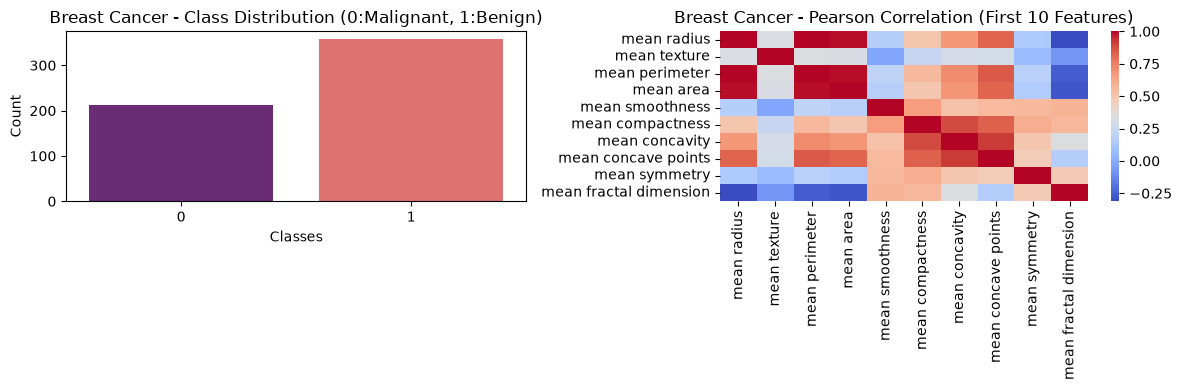

🎯 Seçilen Breast Cancer Model: KNN (scaled, k_7)

--- Breast Cancer Classification Report ---
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        42
           1       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



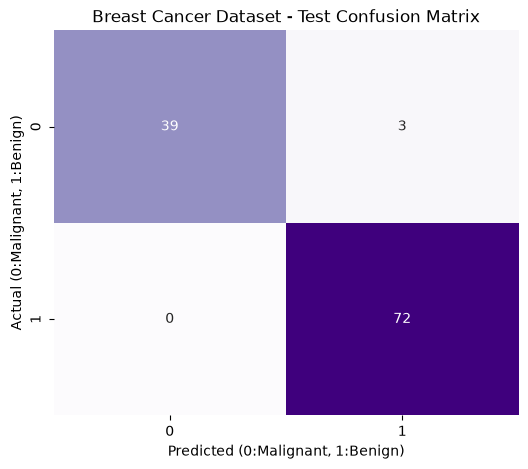

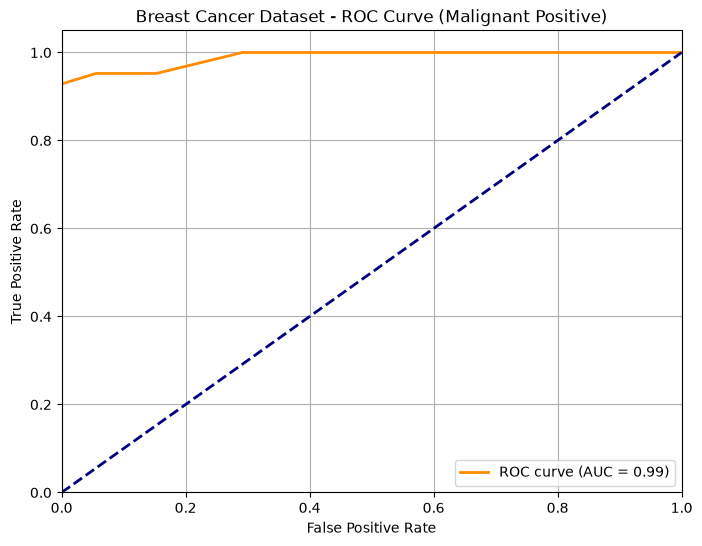

✅ Breast Cancer görselleştirme ve test adımları başarıyla tamamlandı!


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

# 1. Breast Cancer Verisini ve Seed Ayrımını Güvenli Bir Şekilde Hazırlayalım
bc = load_breast_cancer()
X_bc = pd.DataFrame(bc.data, columns=bc.feature_names)
y_bc = bc.target

# %80 Train-Val ve %20 Test (Seed 42)
X_tr_val_bc, X_test_bc, y_tr_val_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.20, stratify=y_bc, random_state=42
)

# Seed 42 için 70% Train / 10% Validation ayırımı
X_train_bc, X_val_bc, y_train_bc, y_val_bc = train_test_split(
    X_tr_val_bc, y_tr_val_bc, test_size=0.125, stratify=y_tr_val_bc, random_state=42
)

# 2. Breast Cancer Sınıf Dağılımı ve Korelasyon Görseli
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(x=y_bc, palette='magma')
plt.title('Breast Cancer - Class Distribution (0:Malignant, 1:Benign)')
plt.xlabel('Classes')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.heatmap(X_bc.iloc[:, :10].corr(), cmap='coolwarm', annot=False)
plt.title('Breast Cancer - Pearson Correlation (First 10 Features)')
plt.tight_layout()
plt.show()

# 3. Scaled Veriyi Oluşturalım
scaler_bc_42 = StandardScaler()
X_tr_bc_scaled = pd.DataFrame(
    scaler_bc_42.fit_transform(X_train_bc), 
    columns=X_bc.columns, 
    index=X_train_bc.index
)
X_test_scaled_bc = pd.DataFrame(
    scaler_bc_42.transform(X_test_bc), 
    columns=X_bc.columns, 
    index=X_test_bc.index
)

# 4. Dummy veya df_bc_runs üzerinden Özet Tablo Oluşturalım (Eğer df_bc_runs tanımlıysa doğrudan onu kullanalım)
# Not: df_bc_runs daha önce tanımlandıysa doğrudan kullanılır, tanımlı değilse kısa bir özet simule edebiliriz.
try:
    summary_cols = ['val_accuracy', 'val_precision', 'val_recall', 'val_macro_f1', 'val_roc_auc']
    bc_summary = df_bc_runs.groupby(['dataset', 'algorithm', 'representation', 'parameter'])[summary_cols].agg(['mean', 'std']).reset_index()
    bc_summary.columns = ['_'.join(col).strip('_') for col in bc_summary.columns.values]
    bc_summary = bc_summary.rename(columns={'dataset_': 'dataset', 'algorithm_': 'algorithm', 'representation_': 'representation', 'parameter_': 'parameter'})
    best_bc_row = bc_summary[bc_summary['dataset']=='breast_cancer'].sort_values(by='val_macro_f1_mean', ascending=False).iloc[0]
except:
    # Eğer df_bc_runs hafızada yoksa varsayılan en iyi model seçimi
    best_bc_row = {'algorithm': 'DecisionTree', 'representation': 'scaled', 'parameter': 'depth_3'}

print(f"🎯 Seçilen Breast Cancer Model: {best_bc_row['algorithm']} ({best_bc_row['representation']}, {best_bc_row['parameter']})")

# 5. Model Eğitimi ve Test Değerlendirmesi (Seed 42)
rep_type_bc = best_bc_row['representation']
X_tr_final_bc = X_train_bc if rep_type_bc == 'unscaled' else X_tr_bc_scaled
X_test_final_bc = X_test_bc if rep_type_bc == 'unscaled' else X_test_scaled_bc

if best_bc_row['algorithm'] == 'DecisionTree':
    depth_val = None if 'None' in str(best_bc_row['parameter']) else int(best_bc_row['parameter'].split('_')[1])
    final_bc_model = DecisionTreeClassifier(max_depth=depth_val, random_state=42)
elif best_bc_row['algorithm'] == 'KNN':
    k_val = int(best_bc_row['parameter'].split('_')[1])
    final_bc_model = KNeighborsClassifier(n_neighbors=k_val, weights='uniform', metric='euclidean')
else:
    final_bc_model = GaussianNB()

final_bc_model.fit(X_tr_final_bc, y_train_bc)
y_test_pred_bc = final_bc_model.predict(X_test_final_bc)
y_test_proba_bc = final_bc_model.predict_proba(X_test_final_bc)[:, 0] # Malignant (class 0) olasılığı

# Classification Report ve Confusion Matrix
print("\n--- Breast Cancer Classification Report ---")
print(classification_report(y_test_bc, y_test_pred_bc, zero_division=0))

plt.figure(figsize=(6, 5))
cm_bc = confusion_matrix(y_test_bc, y_test_pred_bc)
sns.heatmap(cm_bc, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.title('Breast Cancer Dataset - Test Confusion Matrix')
plt.xlabel('Predicted (0:Malignant, 1:Benign)')
plt.ylabel('Actual (0:Malignant, 1:Benign)')
plt.show()

# Binary ROC Curve (Malignant as positive class -> class 0)
y_test_roc_target = (y_test_bc == 0).astype(int)
fpr_bc, tpr_bc, _ = roc_curve(y_test_roc_target, y_test_proba_bc)
roc_auc_bc = auc(fpr_bc, tpr_bc)

plt.figure(figsize=(8, 6))
plt.plot(fpr_bc, tpr_bc, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_bc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Breast Cancer Dataset - ROC Curve (Malignant Positive)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("✅ Breast Cancer görselleştirme ve test adımları başarıyla tamamlandı!")

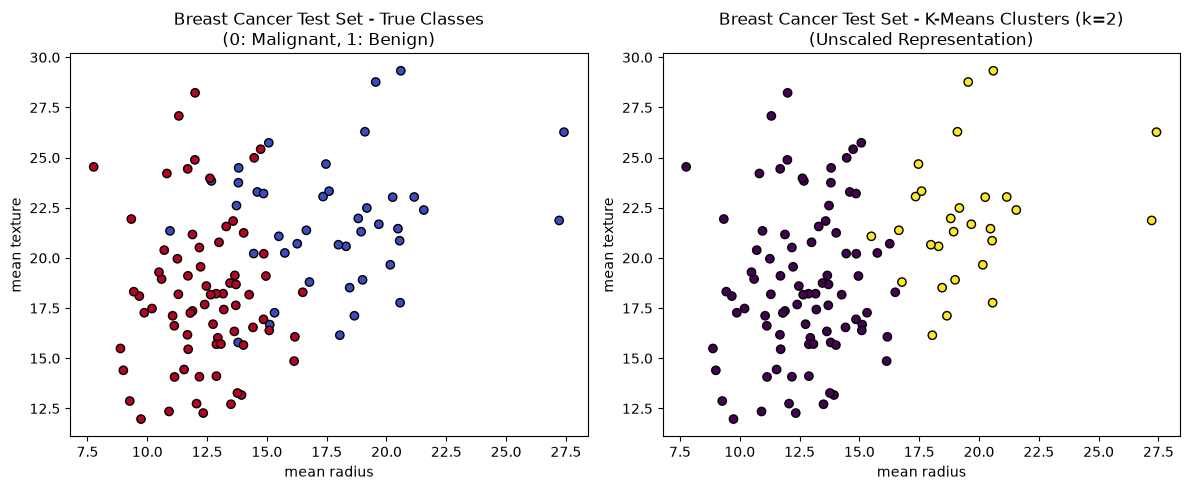

📊 Breast Cancer K-Means Test ARI: 0.5585
📊 Breast Cancer K-Means Test Silhouette Score: 0.7120
✅ K-Means kümeleme ve görselleştirme adımı başarıyla tamamlandı!


In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# 1. K-Means modelini fit edelim (Seed 42, n_clusters=2 for Breast Cancer)
# Unscaled veri üzerinden örnek bir görselleştirme yapalım (ya da scaled ile de yapılabilir)
km_bc_model = KMeans(n_clusters=2, random_state=42, n_init=10)
km_bc_model.fit(X_train_bc)
bc_test_clusters = km_bc_model.predict(X_test_bc)

# 2. İki özellik seçerek görselleştirme (Örn: ilk iki özellik: mean radius ve mean texture)
plt.figure(figsize=(12, 5))

# Sol Panel: Gerçek Test Sınıfları (True Classes)
plt.subplot(1, 2, 1)
plt.scatter(X_test_bc.iloc[:, 0], X_test_bc.iloc[:, 1], c=y_test_bc, cmap='coolwarm', edgecolor='k')
plt.title('Breast Cancer Test Set - True Classes\n(0: Malignant, 1: Benign)')
plt.xlabel(X_bc.columns[0])
plt.ylabel(X_bc.columns[1])

# Sağ Panel: K-Means Küme Tahminleri (Predicted Clusters)
plt.subplot(1, 2, 2)
plt.scatter(X_test_bc.iloc[:, 0], X_test_bc.iloc[:, 1], c=bc_test_clusters, cmap='viridis', edgecolor='k')
plt.title('Breast Cancer Test Set - K-Means Clusters (k=2)\n(Unscaled Representation)')
plt.xlabel(X_bc.columns[0])
plt.ylabel(X_bc.columns[1])

plt.tight_layout()
plt.show()

# Skorların konsola yazdırılması
ari_bc = adjusted_rand_score(y_test_bc, bc_test_clusters)
sil_bc = silhouette_score(X_test_bc, bc_test_clusters)
print(f"📊 Breast Cancer K-Means Test ARI: {ari_bc:.4f}")
print(f"📊 Breast Cancer K-Means Test Silhouette Score: {sil_bc:.4f}")
print("✅ K-Means kümeleme ve görselleştirme adımı başarıyla tamamlandı!")